# B3 – Histogram dan Perbaikan Citra

**SIMUTEH · NIM 2230511115 · SEED 1115**

Notebook ini mendiagnosis mutu citra dengan histogram dan statistik, menguji operasi titik, peregangan kontras, gamma, ekualisasi, CLAHE, serta membandingkan perbaikan pada empat kondisi cahaya.

**Lokasi Google Drive:** simpan folder repository ini di `My Drive/Colab Notebooks/simuteh-2230511115/`. Buka notebook dari subfolder `notebook/`. Sel persiapan akan memasang Google Drive di Colab.

> **Catatan Google Colab:** Jalankan sel persiapan terlebih dahulu dan izinkan akses Google Drive. Pastikan folder `simuteh-2230511115` lengkap berada di `Drive Saya/Colab Notebooks/`. Jika sebelumnya pernah menjalankan versi lama, pilih **Runtime → Restart session** lalu jalankan notebook dari atas.

## 3.1 Persiapan dataset dan fungsi bantu

In [1]:
from pathlib import Path
import sys, subprocess, json, time, platform, importlib.metadata
import importlib, re, os

# Pustaka yang digunakan pada praktikum. Google Colab biasanya sudah menyediakannya.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from IPython.display import display
from time import perf_counter

# 1) Pasang Google Drive bila notebook dijalankan di Google Colab.
try:
    from google.colab import drive
    IN_COLAB = True
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False

# 2) Validasi repository. Folder lama dengan src yang tidak cocok akan dilewati.
DRIVE_NOTEBOOKS = Path('/content/drive/MyDrive/Colab Notebooks')
NIM = '2230511115'
SEED_TARGET = int(NIM[-4:])

_kandidat = [
    DRIVE_NOTEBOOKS / 'simuteh-2230511115',
    DRIVE_NOTEBOOKS / 'simuteh-2230511115' / 'simuteh-2230511115',
    Path.cwd(),
    *Path.cwd().parents,
    Path('/content/simuteh-2230511115'),
]
if DRIVE_NOTEBOOKS.exists():
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob('*/simuteh-2230511115')))
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob('*')))


def _baca_konstanta_seed(path):
    """Membaca deklarasi SEED sederhana, misalnya: SEED = 1115."""
    if not path.is_file():
        return None
    source = path.read_text(encoding='utf-8-sig')
    cocok = re.search(
        r'(?m)^\s*SEED\s*(?::\s*[^=]+)?=\s*(\d+)\s*(?:#.*)?$',
        source,
    )
    return int(cocok.group(1)) if cocok else None


def _folder_repository(p):
    if not p.is_dir():
        return False
    wajib = [
        p / 'src' / 'buat_dataset_sintetis.py',
        p / 'src' / 'utils_cv.py',
        p / 'src' / 'praproses.py',
        p / 'notebook' / 'B1_lingkungan.ipynb',
        p / 'notebook' / 'B2_citra_warna.ipynb',
        p / 'notebook' / 'B3_histogram.ipynb',
        p / 'notebook' / 'B4_penapisan.ipynb',
        p / 'notebook' / 'B5_praproses.ipynb',
    ]
    if not all(x.is_file() for x in wajib):
        return False
    return _baca_konstanta_seed(p / 'src' / 'buat_dataset_sintetis.py') == SEED_TARGET

ROOT = next((p.resolve() for p in _kandidat if _folder_repository(p)), None)
if ROOT is None:
    raise FileNotFoundError(
        'Repository SIMUTEH versi baru tidak ditemukan atau file src tidak cocok. '
        'Hapus folder simuteh-2230511115 yang lama dari Google Drive, lalu unggah '
        'folder baru hasil ekstraksi ZIP secara utuh ke Drive Saya/Colab Notebooks. '
        'Pastikan src/buat_dataset_sintetis.py memuat baris SEED = 1115.'
    )

SRC = ROOT / 'src'
DATA = ROOT / 'data' / 'sintetis'
CITRA = DATA / 'citra'
BERSIH = DATA / 'bersih'
MASK_DAUN = DATA / 'mask_daun'
MASK_BERCAK = DATA / 'mask_bercak'
HASIL = ROOT / 'hasil'
HASIL.mkdir(parents=True, exist_ok=True)
for _folder in (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK):
    _folder.mkdir(parents=True, exist_ok=True)

# 3) Bersihkan cache impor agar modul yang sudah pernah dipanggil tidak tertukar.
for _nama_modul in ('buat_dataset_sintetis', 'utils_cv', 'praproses'):
    sys.modules.pop(_nama_modul, None)
importlib.invalidate_caches()
_src_text = str(SRC.resolve())
sys.path[:] = [_src_text] + [x for x in sys.path if str(x) != _src_text]

# 4) Pastikan nilai SEED pada skrip sama dengan empat digit terakhir NIM.
SCRIPT_DATASET = SRC / 'buat_dataset_sintetis.py'
SEED = _baca_konstanta_seed(SCRIPT_DATASET)
if SEED != SEED_TARGET:
    raise ValueError(
        f'SEED pada {SCRIPT_DATASET} adalah {SEED}; seharusnya {SEED_TARGET}. '
        'Gunakan folder repository SIMUTEH versi baru.'
    )

# 5) Impor fungsi bantu dari src.
from utils_cv import baca, tampil, kontras_bercak, statistik

# 6) Buat dataset 60 citra bila belum ada atau belum lengkap.
label_path = DATA / 'label.csv'
subfolder_dataset = (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK)
dataset_lengkap = label_path.is_file()
if dataset_lengkap:
    try:
        _cek_label = pd.read_csv(label_path)
        dataset_lengkap = (
            len(_cek_label) == 60
            and _cek_label['nama_file'].nunique() == 60
            and all(sum(1 for _ in folder.glob('teh_*.png')) == 60 for folder in subfolder_dataset)
        )
    except Exception:
        dataset_lengkap = False

if not dataset_lengkap:
    print(f'Dataset belum lengkap. Membuat 60 citra sintetis dengan SEED={SEED} ...')
    subprocess.run([sys.executable, str(SCRIPT_DATASET)], cwd=str(ROOT), check=True)

label = pd.read_csv(label_path)
assert len(label) == 60 and label['nama_file'].nunique() == 60, 'Dataset harus berisi 60 citra unik.'
for _folder in subfolder_dataset:
    _jumlah = sum(1 for _ in _folder.glob('teh_*.png'))
    assert _jumlah == 60, f'Folder {_folder.name} harus berisi 60 gambar, ditemukan {_jumlah}.'

KONDISI = ['normal', 'gelap', 'terang', 'kontras_rendah', 'bayangan']
print('Repository aktif:', ROOT)
print('SEED:', SEED, '| Jumlah citra:', len(label), '| Ukuran citra: 640 x 480')


Mounted at /content/drive
Repository aktif: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115
SEED: 1115 | Jumlah citra: 60 | Ukuran citra: 640 x 480


## 3.2 Lembar hitung manual histogram dan operasi titik

Matriks 3 bit dari petunjuk memiliki intensitas 1–4. Tampilkan histogram, peregangan ke 0–7, dan pemetaan ekualisasi. Untuk operasi 8 bit, hitung negatif, perubahan kontras dengan clipping, dan gamma.

In [2]:
M = np.array([[1, 2, 2, 3], [2, 2, 3, 3], [1, 2, 3, 4], [2, 3, 3, 2]], dtype=np.uint8)
values, counts = np.unique(M, return_counts=True)
hist_manual = pd.DataFrame({"r": values, "n": counts})
hist_manual["PDF"] = hist_manual["n"] / M.size
hist_manual["CDF"] = hist_manual["PDF"].cumsum()
hist_manual["7 x CDF"] = 7 * hist_manual["CDF"]
hist_manual["s ekualisasi"] = np.rint(hist_manual["7 x CDF"]).astype(int)
# Pemetaan peregangan min-max ke rentang 0..7.
lo, hi = int(M.min()), int(M.max())
map_stretch = {int(v): int(np.rint((v-lo) * 7 / (hi-lo))) for v in values}
# Pemetaan CDF dengan pembulatan, sesuai perhitungan tabel manual.
map_equalize = {int(r): int(s) for r, s in zip(hist_manual["r"], hist_manual["s ekualisasi"])}
stretch = np.vectorize(map_stretch.get)(M).astype(np.uint8)
equalized = np.vectorize(map_equalize.get)(M).astype(np.uint8)
print("Histogram dan tabel PDF/CDF:"); display(hist_manual)
print("Matriks asli:\n", M)
print("Pemetaan peregangan:", map_stretch, "\nMatriks hasil:\n", stretch)
print("Pemetaan ekualisasi:", map_equalize, "\nMatriks hasil:\n", equalized)

r_neg = 255 - 60
r_kontras_120 = np.clip(1.4 * 120 - 30, 0, 255)
r_kontras_210 = np.clip(1.4 * 210 - 30, 0, 255)
def gamma_pixel(r, gamma): return 255 * (r / 255) ** gamma
print("Negatif r=60:", r_neg)
print("Kontras r=120:", r_kontras_120, "| r=210:", r_kontras_210)
print("Gamma r=100, gamma=0.6:", round(gamma_pixel(100, 0.6)), "| gamma=1.8:", round(gamma_pixel(100, 1.8)))

Histogram dan tabel PDF/CDF:


,r,n,PDF,CDF,7 x CDF,s ekualisasi
0,1,2,0.1250,0.1250,0.8750,1
1,2,7,0.4375,0.5625,3.9375,4
2,3,6,0.3750,0.9375,6.5625,7
3,4,1,0.0625,1.0000,7.0000,7


Matriks asli:
 [[1 2 2 3]
 [2 2 3 3]
 [1 2 3 4]
 [2 3 3 2]]
Pemetaan peregangan: {1: 0, 2: 2, 3: 5, 4: 7} 
Matriks hasil:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]
Pemetaan ekualisasi: {1: 1, 2: 4, 3: 7, 4: 7} 
Matriks hasil:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
Negatif r=60: 195
Kontras r=120: 138.0 | r=210: 255.0
Gamma r=100, gamma=0.6: 145 | gamma=1.8: 47


## 3.3 Diagnosis lima kondisi cahaya dan lima citra kelas ringan

Gunakan `statistik()` dari `utils_cv.py`. Histogram dan persentase piksel gelap/terang dipakai untuk mendukung diagnosis, bukan hanya melihat rerata.

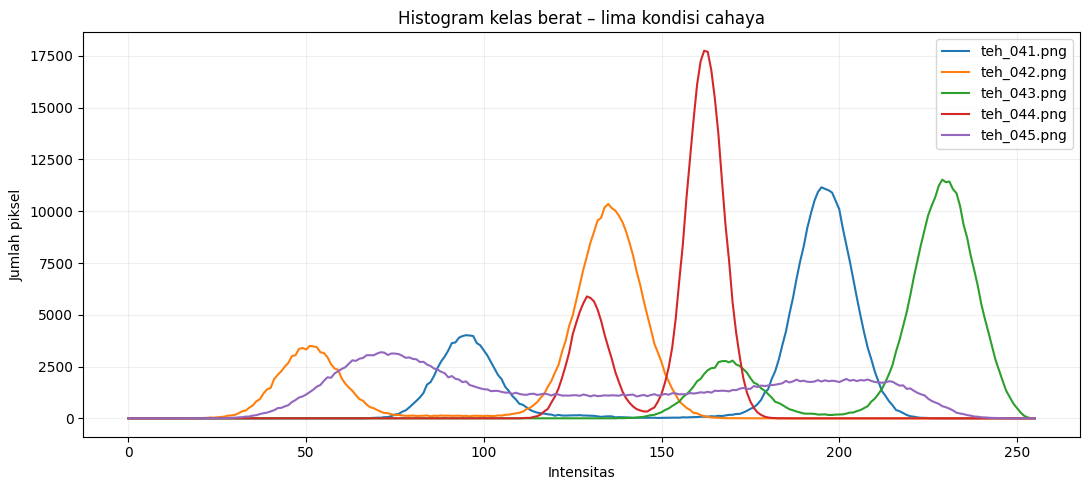

,Citra,rerata,simpangan_baku,min,maks,persen_gelap,persen_terang,Diagnosis,Usulan
0,teh_041.png,168.7,45.1,58,233,0.0,8.1,Normal,Acuan
1,teh_042.png,113.9,37.5,8,176,10.7,0.0,Gelap,Gamma < 1
2,teh_043.png,217.2,25.7,132,255,0.0,79.3,Terang,Gamma > 1; cek kejenuhan
3,teh_044.png,154.0,15.0,108,188,0.0,0.0,Kontras rendah,Peregangan persentil
4,teh_045.png,129.4,56.5,18,249,2.6,12.0,Bayangan,CLAHE lokal


,Citra,rerata,simpangan_baku,min,maks,persen_gelap,persen_terang
0,teh_021.png,177.5,37.8,72,228,0.0,7.7
1,teh_022.png,110.1,39.4,17,163,21.7,0.0
2,teh_023.png,212.2,25.8,132,253,0.0,72.4
3,teh_024.png,153.0,13.5,105,185,0.0,0.0
4,teh_025.png,118.0,49.1,30,238,1.0,5.4


In [3]:
nama_berat = [f"teh_{i:03d}.png" for i in range(41, 46)]
nama_ringan = [f"teh_{i:03d}.png" for i in range(21, 26)]

baris = []
fig, ax = plt.subplots(figsize=(11, 5))
for nama in nama_berat:
    g = cv2.cvtColor(baca(CITRA / nama), cv2.COLOR_BGR2GRAY)
    st = statistik(g)
    baris.append({"Citra": nama, **st})
    hist = cv2.calcHist([g], [0], None, [256], [0, 256]).ravel()
    ax.plot(hist, label=nama)
ax.set_xlabel("Intensitas"); ax.set_ylabel("Jumlah piksel")
ax.set_title("Histogram kelas berat – lima kondisi cahaya"); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(HASIL / "b3_histogram_5kondisi.png", dpi=160); plt.show()

tabel_berat = pd.DataFrame(baris)
tabel_berat["Diagnosis"] = ["Normal", "Gelap", "Terang", "Kontras rendah", "Bayangan"]
tabel_berat["Usulan"] = ["Acuan", "Gamma < 1", "Gamma > 1; cek kejenuhan", "Peregangan persentil", "CLAHE lokal"]
display(tabel_berat)
tabel_berat.to_csv(HASIL / "b3_diagnosis_berat.csv", index=False)

baris_ringan = []
for nama in nama_ringan:
    g = cv2.cvtColor(baca(CITRA / nama), cv2.COLOR_BGR2GRAY)
    baris_ringan.append({"Citra": nama, **statistik(g)})
tabel_ringan = pd.DataFrame(baris_ringan)
display(tabel_ringan)
tabel_ringan.to_csv(HASIL / "b3_diagnosis_ringan.csv", index=False)

## 3.4 Operasi titik dan metode perbaikan pada citra bayangan (teh_045)

,Metode,KB,Simpangan baku,Min,Maks
0,Asli,1.93,56.48,18,249
1,Negatif,1.93,56.48,6,237
2,Cerah +50,1.93,54.28,68,255
3,Kontras alpha=1.5 beta=-40,1.93,78.88,0,255
4,Regang persentil 2–98,2.05,80.88,0,255
5,Gamma 0.5,1.64,40.53,67,251
6,Gamma 1.8,2.51,61.24,2,244
7,Ekualisasi global,1.48,73.48,0,255
8,CLAHE 2.0 / 8x8,1.61,46.48,10,251


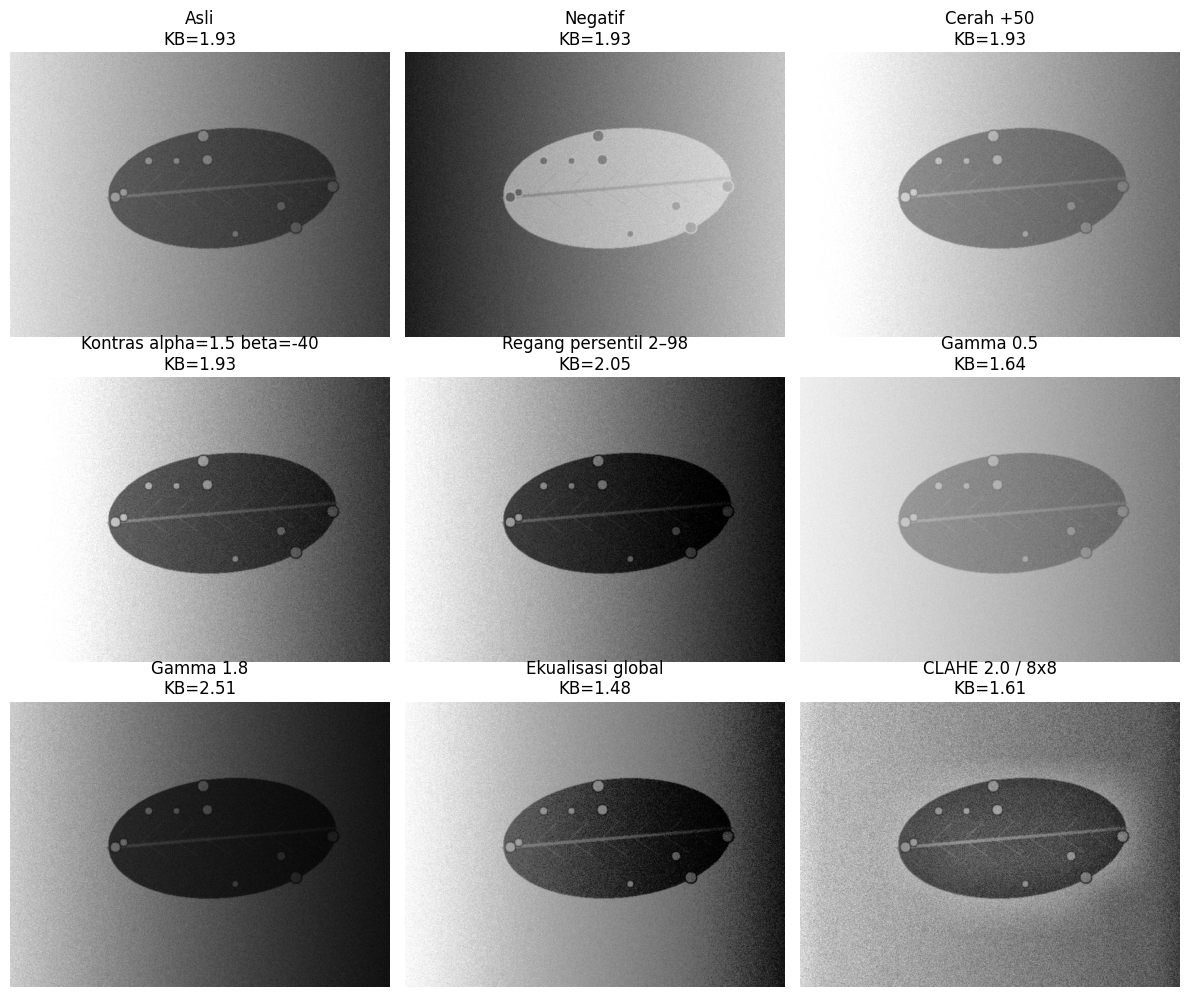

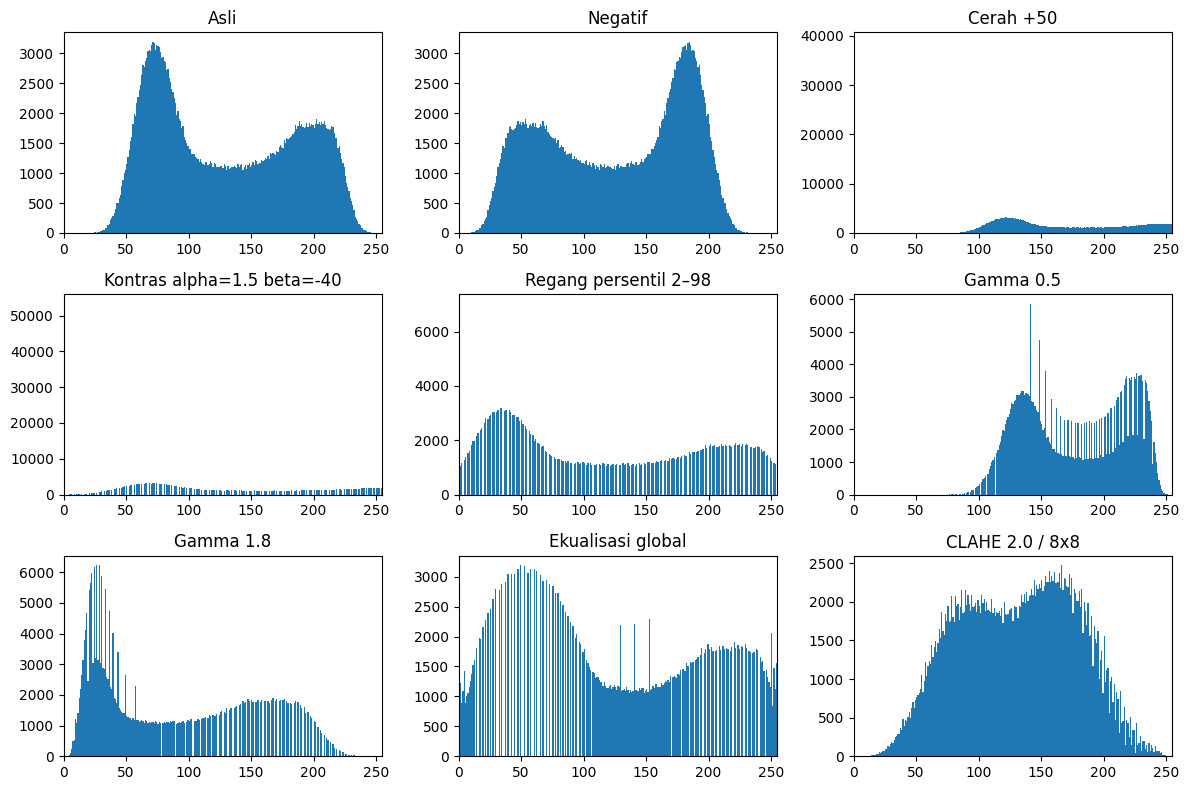

In [4]:
nama = "teh_045.png"
im = baca(CITRA / nama)
md0 = baca(MASK_DAUN / nama, gray=True)
mb0 = baca(MASK_BERCAK / nama, gray=True)
gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

def gamma_lut(gamma):
    lut = 255 * (np.arange(256, dtype=np.float32) / 255.0) ** gamma
    return np.clip(lut, 0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))
regang = np.clip((gray.astype(float)-rmin) / max(rmax-rmin, 1e-6) * 255, 0, 255).astype(np.uint8)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hasil = {
    "Asli": gray,
    "Negatif": 255 - gray,
    "Cerah +50": cv2.add(gray, 50),
    "Kontras alpha=1.5 beta=-40": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "Regang persentil 2–98": regang,
    "Gamma 0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "Gamma 1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "Ekualisasi global": cv2.equalizeHist(gray),
    "CLAHE 2.0 / 8x8": clahe.apply(gray),
}
baris_metode = []
for nm, out in hasil.items():
    baris_metode.append([nm, kontras_bercak(out, md0, mb0), out.std(), out.min(), out.max()])
tabel_metode = pd.DataFrame(baris_metode, columns=["Metode", "KB", "Simpangan baku", "Min", "Maks"]).round(2)
display(tabel_metode)
tabel_metode.to_csv(HASIL / "b3_perbaikan_teh045.csv", index=False)

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, (nm, out) in zip(axes.flat, hasil.items()):
    ax.imshow(out, cmap="gray", vmin=0, vmax=255); ax.set_title(f"{nm}\nKB={kontras_bercak(out, md0, mb0):.2f}"); ax.axis("off")
plt.tight_layout(); plt.savefig(HASIL / "b3_panel_perbaikan.png", dpi=150); plt.show()
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, (nm, out) in zip(axes.flat, hasil.items()):
    ax.hist(out.ravel(), bins=256, range=(0, 256)); ax.set_title(nm); ax.set_xlim(0, 255)
plt.tight_layout(); plt.savefig(HASIL / "b3_histogram_perbaikan.png", dpi=150); plt.show()

## 3.5 Eksperimen parameter CLAHE dan citra warna

Bandingkan clipLimit 1, 2, 4 dengan tile 4, 8, 16. Kemudian bandingkan CLAHE pada kanal V dengan CLAHE pada setiap kanal BGR.

,clipLimit,tile,KB,Simpangan baku
0,1.0,4,2.25,50.70
1,1.0,8,1.93,50.14
2,1.0,16,2.01,50.19
3,2.0,4,1.92,47.99
4,2.0,8,1.61,46.48
5,2.0,16,1.65,46.68
6,4.0,4,1.42,48.60
7,4.0,8,1.21,45.37
8,4.0,16,1.27,44.83


,Metode,KB grayscale
0,Asli,1.93
1,CLAHE kanal V,1.71
2,CLAHE tiap kanal BGR,1.55


True

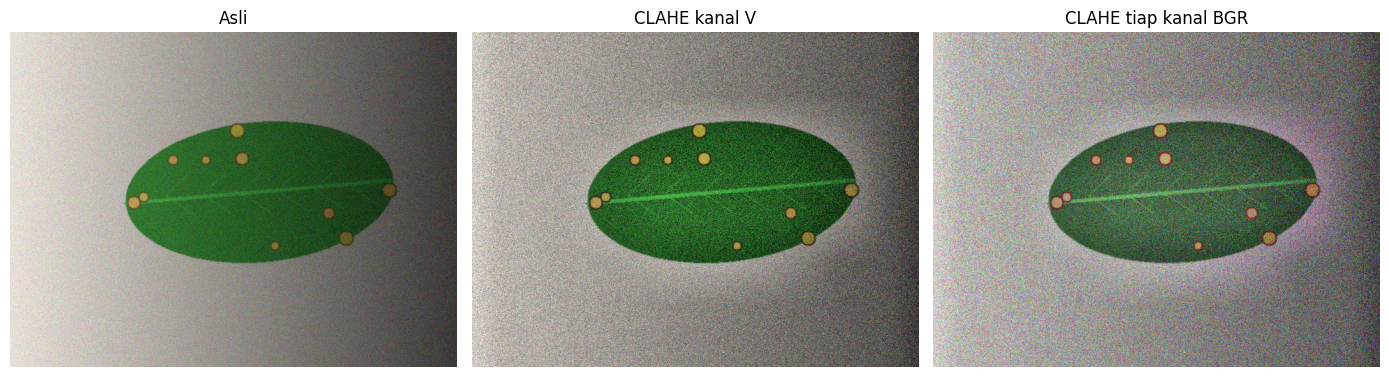

In [5]:
baris_clahe = []
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        out = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        baris_clahe.append([clip, tile, kontras_bercak(out, md0, mb0), out.std()])
tabel_clahe = pd.DataFrame(baris_clahe, columns=["clipLimit", "tile", "KB", "Simpangan baku"]).round(2)
display(tabel_clahe)
tabel_clahe.to_csv(HASIL / "b3_parameter_clahe.csv", index=False)

obj = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = obj.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([obj.apply(ch) for ch in cv2.split(im)])
tampil([im, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"], baris=1, ukuran=(14, 4))
perbandingan_warna = pd.DataFrame([
    ["Asli", kontras_bercak(gray, md0, mb0)],
    ["CLAHE kanal V", kontras_bercak(cv2.cvtColor(via_v, cv2.COLOR_BGR2GRAY), md0, mb0)],
    ["CLAHE tiap kanal BGR", kontras_bercak(cv2.cvtColor(via_bgr, cv2.COLOR_BGR2GRAY), md0, mb0)],
], columns=["Metode", "KB grayscale"])
display(perbandingan_warna.round(2))
perbandingan_warna.to_csv(HASIL / "b3_clahe_warna.csv", index=False)
cv2.imwrite(str(HASIL / "b3_clahe_v.png"), via_v)
cv2.imwrite(str(HASIL / "b3_clahe_bgr.png"), via_bgr)

## 3.6 Perbaikan per kondisi untuk kelas berat dan ringan

Aturan eksperimen: gelap → gamma 0,6; terang → gamma 1,8; kontras rendah → peregangan persentil 2–98; bayangan → CLAHE 2,0/8×8. Periksa hasil pada kelas berat dan ringan.

,Kondisi,Kelas,Citra,Metode,KB sebelum,KB sesudah
0,gelap,berat,teh_042.png,Gamma 0.6,3.60,3.05
1,gelap,ringan,teh_022.png,Gamma 0.6,5.12,4.17
2,terang,berat,teh_043.png,Gamma 1.8,3.02,3.28
3,terang,ringan,teh_023.png,Gamma 1.8,1.55,1.70
4,kontras_rendah,berat,teh_044.png,Regang persentil 2–98,2.87,3.02
5,kontras_rendah,ringan,teh_024.png,Regang persentil 2–98,1.96,2.11
6,bayangan,berat,teh_045.png,CLAHE 2.0/8x8,1.93,1.61
7,bayangan,ringan,teh_025.png,CLAHE 2.0/8x8,0.45,0.94


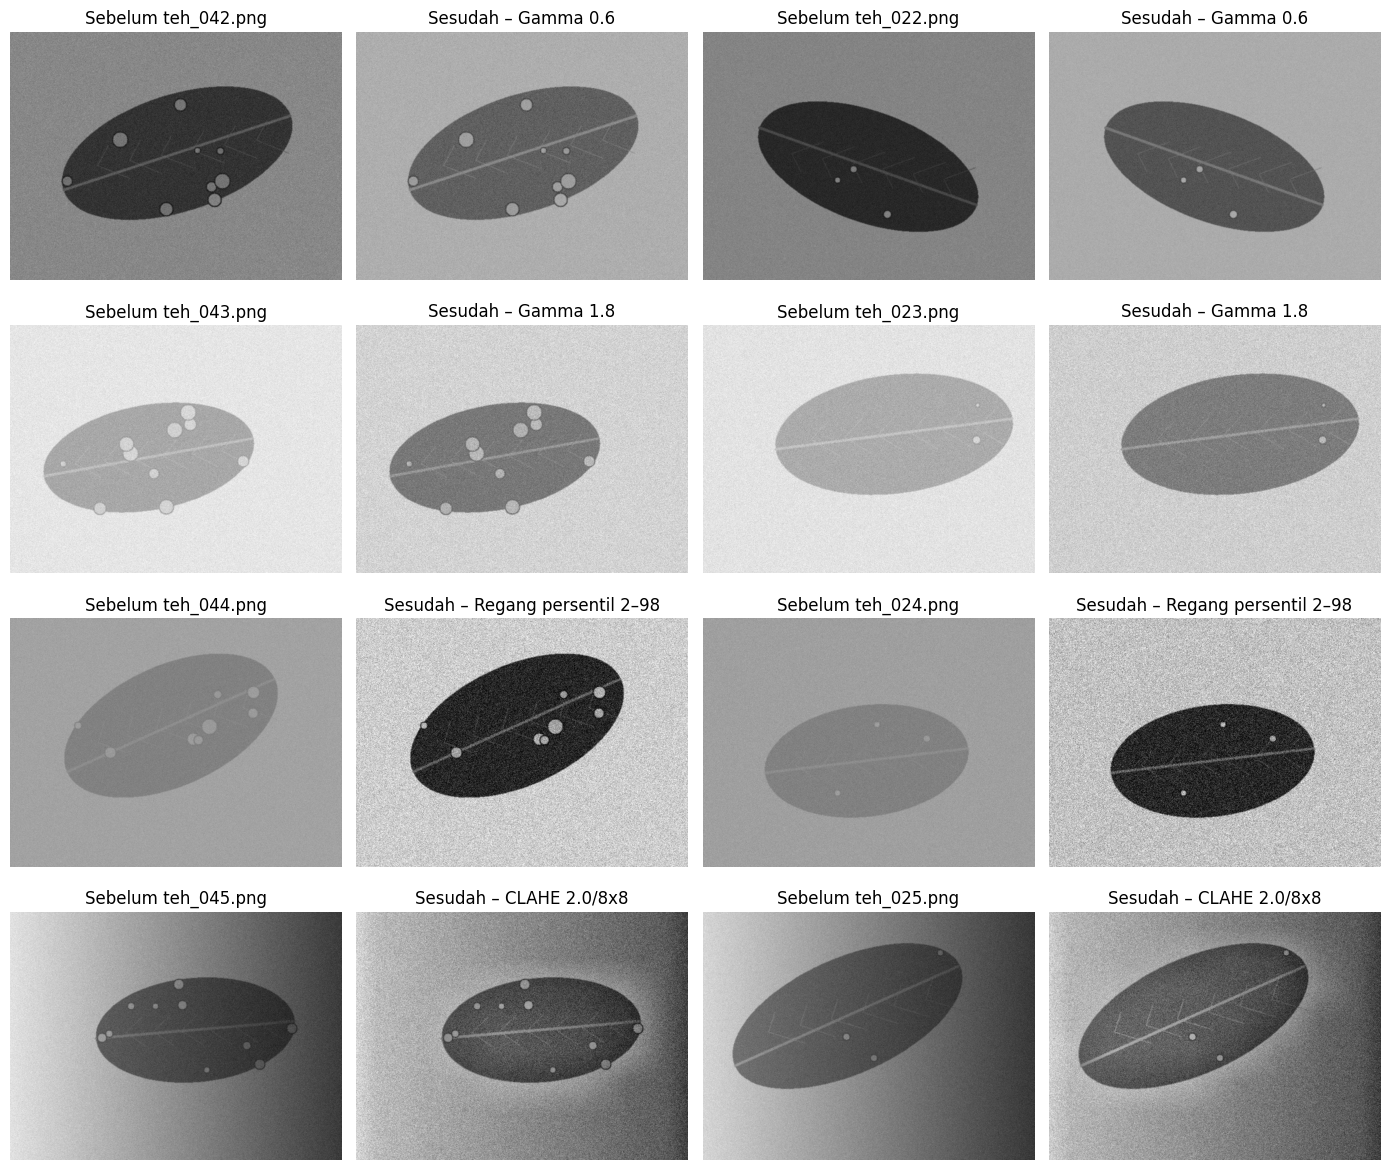

In [6]:
def perbaiki_kondisi(gray_img, kondisi):
    if kondisi == "gelap":
        return cv2.LUT(gray_img, gamma_lut(0.6)), "Gamma 0.6"
    if kondisi == "terang":
        return cv2.LUT(gray_img, gamma_lut(1.8)), "Gamma 1.8"
    if kondisi == "kontras_rendah":
        lo, hi = np.percentile(gray_img, (2, 98))
        out = np.clip((gray_img.astype(float)-lo) / max(hi-lo, 1e-6) * 255, 0, 255).astype(np.uint8)
        return out, "Regang persentil 2–98"
    if kondisi == "bayangan":
        return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray_img), "CLAHE 2.0/8x8"
    return gray_img, "Tanpa perbaikan"

baris_kondisi, panel = [], []
pasangan = [("gelap", 42, 22), ("terang", 43, 23), ("kontras_rendah", 44, 24), ("bayangan", 45, 25)]
for kondisi, no_berat, no_ringan in pasangan:
    for kelas, nomor in [("berat", no_berat), ("ringan", no_ringan)]:
        nama_file = f"teh_{nomor:03d}.png"
        im0 = baca(CITRA / nama_file)
        g0 = cv2.cvtColor(im0, cv2.COLOR_BGR2GRAY)
        m_d = baca(MASK_DAUN / nama_file, gray=True)
        m_b = baca(MASK_BERCAK / nama_file, gray=True)
        out, metode = perbaiki_kondisi(g0, kondisi)
        baris_kondisi.append([kondisi, kelas, nama_file, metode, kontras_bercak(g0, m_d, m_b), kontras_bercak(out, m_d, m_b)])
        panel.append((g0, out, nama_file, metode))
tabel_kondisi = pd.DataFrame(baris_kondisi, columns=["Kondisi", "Kelas", "Citra", "Metode", "KB sebelum", "KB sesudah"]).round(2)
display(tabel_kondisi)
tabel_kondisi.to_csv(HASIL / "b3_perbaikan_per_kondisi.csv", index=False)
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for i, (before, after, nama_file, metode) in enumerate(panel):
    r = i // 2; c = (i % 2) * 2
    axes[r, c].imshow(before, cmap="gray", vmin=0, vmax=255); axes[r, c].set_title(f"Sebelum {nama_file}"); axes[r, c].axis("off")
    axes[r, c+1].imshow(after, cmap="gray", vmin=0, vmax=255); axes[r, c+1].set_title(f"Sesudah – {metode}"); axes[r, c+1].axis("off")
plt.tight_layout(); plt.savefig(HASIL / "b3_panel_empat_kondisi.png", dpi=150); plt.show()

## 3.7 Pertanyaan analisis P3

Jawab di laporan dengan merujuk bukti sendiri: **P3.1** informasi yang hilang saat nilai 3 dan 4 dipetakan sama; **P3.2** ekualisasi global dibanding CLAHE pada bayangan; **P3.3** kondisi min–maks gagal dan contoh ekstrem; **P3.4** alasan CLAHE kanal V; **P3.5** apakah parameter perlu adaptif untuk tiap kondisi; **P3.6** risiko perbaikan berlebihan dan pencegahannya.

**Bukti Bagian 3:** histogram dan diagnosis lima kondisi, tabel perbaikan `teh_045`, eksperimen parameter CLAHE, dan panel sebelum/sesudah empat kondisi.